<a href="https://colab.research.google.com/github/Lourdes-Churacutipa/Repositorio-de-lourdes/blob/main/Lab9_4_Transformers_Fundacionales_Peru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# La Siguiente Generación: Transformers y Modelos Fundacionales
## Ciencia de Datos Ambientales – Aplicado al Perú

**Duración:** 90 minutos · **Entorno:** Google Colab (recomendado: *Entorno de ejecución → Cambiar tipo → GPU T4*, aunque funciona en CPU)

Continuación del Lab 9_3 (RNN/LSTM). Usamos **la misma cuenca** (río Majes en Huatiapa, CAMELS-PE) para comparar generaciones de modelos con los mismos datos.

---

### ¿Cuál es la "siguiente generación"?

| Generación | Años | Idea clave | Lab |
|---|---|---|---|
| Perceptrón / MLP | 1958 / 1986 | Neuronas + retropropagación | 9_1 |
| CNN | 1989 / 2012 | Filtros con pesos compartidos en el **espacio** | 9_2 |
| RNN / LSTM | 1986 / 1997 | Memoria recurrente en el **tiempo** | 9_3 |
| **Transformer** | **2017** | **Atención**: cada elemento mira directamente a todos los demás | **9_4** |
| **Modelos fundacionales** | **2021 →** | Un Transformer **enorme, preentrenado** con datos masivos y reutilizable en tareas nuevas | **9_4** |

Los modelos fundacionales cambian la forma de trabajar:

> **Antes:** recolectar datos de *tu* problema → entrenar *tu* modelo desde cero.
>
> **Ahora:** tomar un modelo ya entrenado con millones de series, imágenes o textos → usarlo **directamente** (*zero-shot*) o **ajustarlo** con pocos datos (*fine-tuning*).

### Objetivos de aprendizaje

1. Explicar las limitaciones de las RNN/LSTM que motivaron los Transformers.
2. Describir las piezas de un Transformer: *tokens*, codificación posicional, auto-atención multi-cabeza, conexiones residuales y normalización.
3. Construir y entrenar un Transformer en Keras para caudales, y **visualizar a qué días presta atención**.
4. Explicar qué es un **modelo fundacional** y cómo se usa en modo *zero-shot*.
5. Pronosticar caudales con **Chronos** (Amazon), un modelo fundacional de series de tiempo, sin entrenarlo, y obtener **pronósticos probabilísticos**.
6. Comparar críticamente las generaciones: precisión, datos necesarios, costo, interpretabilidad.

In [ ]:
# Instalar lo necesario si el entorno no lo trae (la primera vez tarda 1–2 minutos)
import importlib.util, subprocess, sys

for paquete, pip_nombre in [('tensorflow', 'tensorflow'), ('chronos', 'chronos-forecasting')]:
    if importlib.util.find_spec(paquete) is None:
        print(f'Instalando {pip_nombre}...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pip_nombre])

import tensorflow as tf
import torch
print(f'TensorFlow {tf.__version__} | PyTorch {torch.__version__} | GPU: {torch.cuda.is_available()}')

Instalando chronos-forecasting...
TensorFlow 2.21.0 | PyTorch 2.14.1+cu130 | GPU: True


In [ ]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# 1. ¿Por qué ir más allá de la LSTM?

En el Lab 9_3 vimos que la LSTM resuelve el gradiente desvaneciente con su estado de celda. Pero tiene tres límites estructurales:

| Límite de la RNN/LSTM | Consecuencia | Cómo lo resuelve el Transformer |
|---|---|---|
| **Procesamiento secuencial:** el paso $t$ necesita terminar el paso $t-1$ | No se puede paralelizar; entrenar con datos masivos es lento | Procesa **todos los pasos a la vez** (ideal para GPU) |
| **Cuello de botella:** todo el pasado se comprime en un vector de tamaño fijo | La información lejana se diluye | Cada paso **accede directamente** a todos los demás |
| **Camino largo:** la información del día 1 atraviesa 179 pasos para llegar al día 180 | Dependencias muy lejanas siguen siendo difíciles | El camino entre dos días cualesquiera tiene **longitud 1** |

El paralelismo es la razón por la que los Transformers pudieron **escalar** a miles de millones de parámetros y billones de datos. Ese escalado es lo que dio origen a los modelos fundacionales.

# 2. Anatomía de un Transformer

```
 Entrada: 180 días × 6 variables
        │
 [1] Embedding de tokens ── cada día se proyecta a un vector de d_model números
        │
 [2] + Codificación posicional ── le dice al modelo QUÉ día es cada token
        │
 ┌──────▼──────────────────────────────┐
 │ [3] Auto-atención multi-cabeza      │  × N bloques
 │ [4] Suma residual + LayerNorm       │
 │ [5] Red feed-forward (por posición) │
 │     Suma residual + LayerNorm       │
 └──────┬──────────────────────────────┘
        │
 [6] Cabeza de salida ── Dense(1): caudal
```

## 2.1 Tokens y embeddings

Un Transformer trabaja con una **secuencia de tokens**, y cada token es un vector:

| Dominio | Token |
|---|---|
| Texto (GPT, Claude) | Una palabra o fragmento de palabra |
| Imágenes (Vision Transformer) | Un parche de 16×16 píxeles |
| Series de tiempo (este lab) | **Un día** con sus 6 variables meteorológicas |
| Chronos | Un valor escalado y cuantizado en uno de 4 096 "tokens" (Chronos original), o un parche de varios valores consecutivos (Chronos-Bolt, Chronos-2) |

Como vimos en el Lab 9_3, el **embedding** es un encoder aprendido. Aquí es una capa `Dense(d_model)` que convierte los 6 valores de cada día en un vector de 32 números.

## 2.2 Codificación posicional: la atención no sabe de orden

La auto-atención es un promedio ponderado: si desordenas los días, obtienes el mismo resultado desordenado. Necesitamos **inyectar la posición**. El Transformer original suma a cada token un patrón de senos y cosenos de distintas frecuencias:

$$PE_{(pos,\,2i)} = \sin\!\left(\frac{pos}{10000^{2i/d}}\right) \qquad PE_{(pos,\,2i+1)} = \cos\!\left(\frac{pos}{10000^{2i/d}}\right)$$

Es la misma idea que el seno/coseno del día del año del Lab 9_3, pero con **muchas frecuencias a la vez**: las rápidas distinguen días vecinos y las lentas distinguen meses.

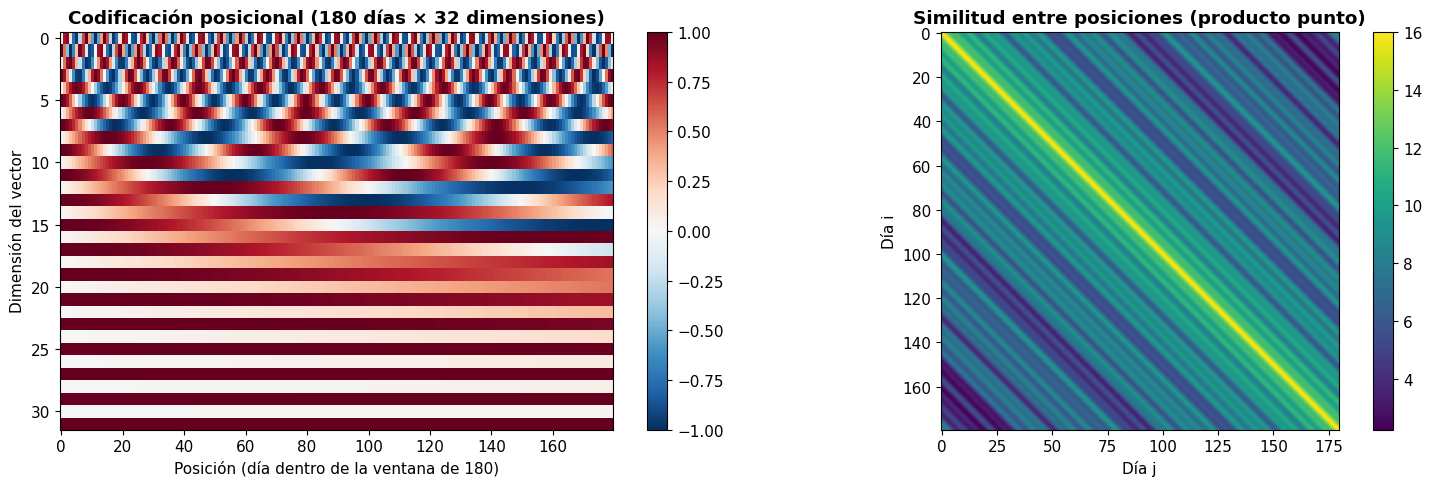

La diagonal brillante indica que los días cercanos tienen codificaciones parecidas.


In [ ]:
def codificacion_posicional(largo, d_model):
    pos = np.arange(largo)[:, None]
    i = np.arange(d_model)[None, :]
    angulos = pos / np.power(10000, (2 * (i // 2)) / d_model)
    return np.where(i % 2 == 0, np.sin(angulos), np.cos(angulos)).astype('float32')

PE = codificacion_posicional(180, 32)

fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
im = ejes[0].imshow(PE.T, aspect='auto', cmap='RdBu_r')
ejes[0].set_xlabel('Posición (día dentro de la ventana de 180)'); ejes[0].set_ylabel('Dimensión del vector')
ejes[0].set_title('Codificación posicional (180 días × 32 dimensiones)', fontweight='bold')
plt.colorbar(im, ax=ejes[0])

similitud = PE @ PE.T
im = ejes[1].imshow(similitud, cmap='viridis')
ejes[1].set_xlabel('Día j'); ejes[1].set_ylabel('Día i')
ejes[1].set_title('Similitud entre posiciones (producto punto)', fontweight='bold')
plt.colorbar(im, ax=ejes[1])
plt.tight_layout(); plt.show()
print('La diagonal brillante indica que los días cercanos tienen codificaciones parecidas.')

## 2.3 Auto-atención y atención multi-cabeza

Repaso del Lab 9_3: **comparar, ponderar, combinar**.

$$\text{Atención}(Q, K, V) = \text{softmax}\!\left(\frac{QK^T}{\sqrt{d_k}}\right) V$$

- **Multi-cabeza:** en lugar de una sola atención, se ejecutan $h$ atenciones en paralelo con distintas matrices $W_Q, W_K, W_V$. Una cabeza puede especializarse en "la lluvia de la última semana" y otra en "la temporada húmeda pasada". Sus salidas se concatenan.
- **Máscara causal:** en un modelo que **genera token a token** (GPT, Claude, o el decoder del Chronos original), cada posición solo puede mirar al **pasado**. Se fuerza poniendo $-\infty$ en los puntajes del futuro antes del softmax. Un encoder, en cambio, mira toda la secuencia en ambas direcciones.

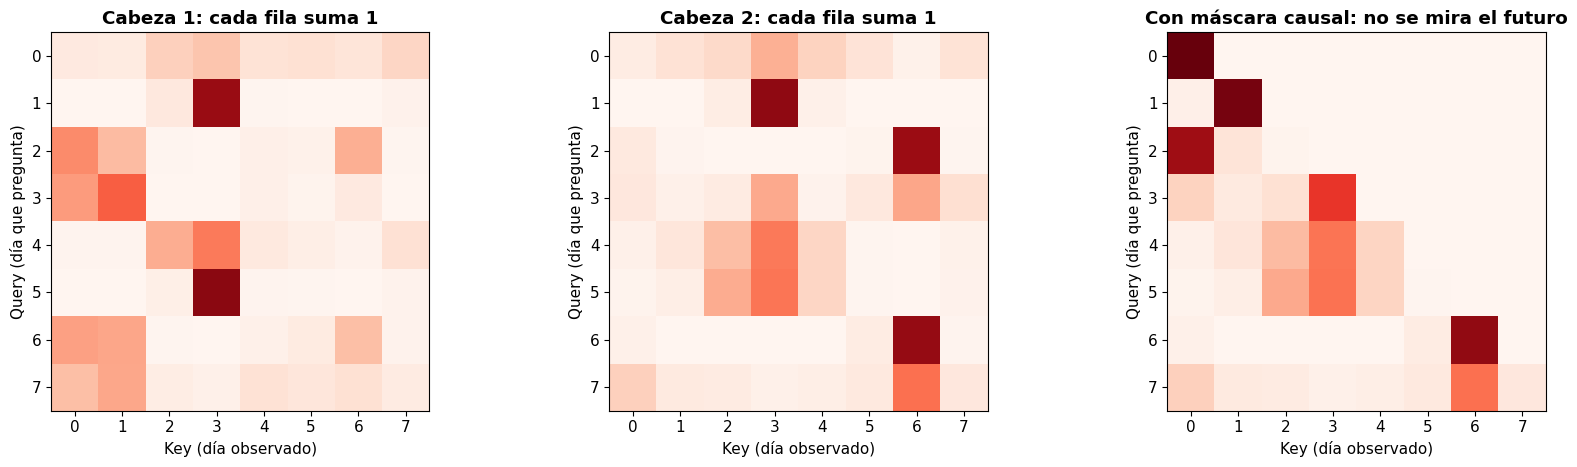

In [ ]:
def softmax(x, eje=-1):
    e = np.exp(x - np.max(x, axis=eje, keepdims=True))
    return e / e.sum(axis=eje, keepdims=True)

def atencion(Q, K, V, mascara=None):
    puntajes = Q @ K.T / np.sqrt(K.shape[-1])
    if mascara is not None:
        puntajes = np.where(mascara, puntajes, -np.inf)   # posiciones prohibidas → peso 0
    A = softmax(puntajes)
    return A @ V, A

rng = np.random.default_rng(0)
T, d = 8, 4
X = rng.normal(size=(T, d))                               # 8 días, cada uno un vector de 4 números

fig, ejes = plt.subplots(1, 3, figsize=(17, 4.8))
for cabeza in range(2):                                    # dos cabezas = dos juegos de pesos distintos
    W_Q, W_K, W_V = (rng.normal(size=(d, d)) for _ in range(3))
    _, A = atencion(X @ W_Q, X @ W_K, X @ W_V)
    ejes[cabeza].imshow(A, cmap='Reds', vmin=0, vmax=1)
    ejes[cabeza].set_title(f'Cabeza {cabeza + 1}: cada fila suma 1', fontweight='bold')

causal = np.tril(np.ones((T, T), dtype=bool))             # triangular inferior: solo pasado
_, A_causal = atencion(X @ W_Q, X @ W_K, X @ W_V, mascara=causal)
ejes[2].imshow(A_causal, cmap='Reds', vmin=0, vmax=1)
ejes[2].set_title('Con máscara causal: no se mira el futuro', fontweight='bold')
for ax in ejes:
    ax.set_xlabel('Key (día observado)'); ax.set_ylabel('Query (día que pregunta)')
    ax.set_xticks(range(T)); ax.set_yticks(range(T))
plt.tight_layout(); plt.show()

## 2.4 Conexiones residuales, LayerNorm y feed-forward

- **Residual** ($x + \text{Atención}(x)$): la información original "salta" el bloque, y el gradiente fluye sin desvanecerse aunque haya decenas de bloques. Es la misma idea de la "autopista" del estado de celda de la LSTM.
- **LayerNorm:** normaliza cada vector para estabilizar el entrenamiento.
- **Feed-forward:** una pequeña red densa aplicada a cada posición por separado. La atención **mezcla** información entre días y la feed-forward la **procesa**.

### Tres familias

| Variante | Atención | Uso | Ejemplos |
|---|---|---|---|
| Solo encoder | Bidireccional | Comprender / predecir a partir de toda la secuencia | BERT, ViT, **Chronos-2**, **nuestro modelo de caudales** |
| Solo decoder | Causal | Generar el siguiente token | GPT, Claude |
| Encoder–decoder | Encoder bidireccional + decoder | Transformar una secuencia en otra | Traducción, T5, **Chronos original** y **Chronos-Bolt** (ambos basados en T5) |

**La familia Chronos usa dos formas de pronosticar:**

- **Autorregresiva:** el **Chronos original** genera el pronóstico token a token, como un modelo de lenguaje. Muestrea muchas trayectorias posibles y de ellas obtiene la incertidumbre.
- **Directa multipaso:** **Chronos-Bolt** y **Chronos-2** producen los cuantiles de todos los días del horizonte de una sola vez. Es mucho más rápido y es lo que usamos en este lab.

# 3. Datos: río Majes en Huatiapa (CAMELS-PE)

Mismos datos y mismos periodos que el Lab 9_3:
- **Entrenamiento** 1998–2010, **validación** 2011–2015 y **prueba** 2016–2020.
- **Entradas:** precipitación (PISCOp), temperaturas (PISCOt), radiación y presión de vapor (ERA5-Land).
- **Referencias:** el caudal observado del SENAMHI y el modelo hidrológico **PISCO-ARNOVIC**.

In [ ]:
GAUGE = 'PE_204617'                               # Huatiapa
ID_DRIVE = '1g5QSLwgXajupJElE4bXxmwe89x22arny'    # archivo compartido en Google Drive (~1.1 MB)
ARCHIVO = f'{GAUGE}.csv'

if not os.path.exists(ARCHIVO):
    try:
        import gdown                              # preinstalado en Google Colab
        gdown.download(id=ID_DRIVE, output=ARCHIVO, quiet=False)
    except ImportError:
        import urllib.request
        urllib.request.urlretrieve(f'https://drive.google.com/uc?export=download&id={ID_DRIVE}', ARCHIVO)

camels = pd.read_csv(ARCHIVO, parse_dates=['date'], index_col='date')

def nse(obs, sim):
    return 1 - np.sum((obs - sim) ** 2) / np.sum((obs - obs.mean()) ** 2)

def kge(obs, sim):
    r = np.corrcoef(obs, sim)[0, 1]
    return 1 - np.sqrt((r - 1) ** 2 + (sim.std() / obs.std() - 1) ** 2 + (sim.mean() / obs.mean() - 1) ** 2)

print(f"Periodo: {camels.index.min().date()} a {camels.index.max().date()}  ({len(camels)} días)")
print(f"Días con caudal observado: {camels['flow_obs'].notna().sum()} ({camels['flow_obs'].notna().mean():.0%})")

Downloading...
From: https://drive.google.com/uc?id=1g5QSLwgXajupJElE4bXxmwe89x22arny
To: /content/PE_204617.csv
100%|██████████| 1.14M/1.14M [00:00<00:00, 11.6MB/s]

Periodo: 1981-01-01 a 2025-12-31  (16436 días)
Días con caudal observado: 7951 (48%)


In [ ]:
VARS_MET = ['prec', 'tmean', 'tmax', 'tmin', 'srad', 'vprp']
df = camels.loc['1996-01-01':'2020-12-31'].copy()
entrena = df.index <= '2010-12-31'

X_met = df[VARS_MET].values.astype('float32')
X_met_n = (X_met - X_met[entrena].mean(0)) / X_met[entrena].std(0)

q_obs = df['flow_obs'].values
q_log = np.log(q_obs + 0.05)
q_media, q_desv = np.nanmean(q_log[entrena]), np.nanstd(q_log[entrena])
q_n = (q_log - q_media) / q_desv

def a_caudal(v):
    return np.maximum(np.exp(np.asarray(v) * q_desv + q_media) - 0.05, 0)

def crear_ventanas(X, ventana, horizonte=0):
    # Ventanas que terminan en t; el objetivo es el caudal observado en t + horizonte
    t = np.arange(ventana - 1, len(X) - horizonte)
    t = t[~np.isnan(q_obs[t + horizonte]) & (df.index[t] >= '1998-01-01')]
    Xw = np.stack([X[i - ventana + 1:i + 1] for i in t])
    fechas = df.index[t + horizonte]
    periodos = {'entrena': fechas <= '2010-12-31',
                'valida': (fechas > '2010-12-31') & (fechas <= '2015-12-31'),
                'prueba': fechas >= '2016-01-01'}
    return Xw, t, fechas, periodos

def entrenar(modelo, Xw, y, periodos, lr=1e-3, epocas=40):
    modelo.compile(optimizer=keras.optimizers.Adam(lr), loss='mse')
    e, v = periodos['entrena'], periodos['valida']
    t0 = time.time()
    hist = modelo.fit(Xw[e], y[e], epochs=epocas, batch_size=128, validation_data=(Xw[v], y[v]),
                      callbacks=[keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True)],
                      verbose=0)
    print(f"  {modelo.name:<12s} {modelo.count_params():>7,d} parámetros | "
          f"{len(hist.history['loss']):2d} épocas | {time.time() - t0:5.1f} s")
    return hist

# 4. Práctica A: un Transformer para simular caudales

Misma tarea que la A1 del Lab 9_3: con **180 días de meteorología**, estimar el caudal de hoy. Construimos el Transformer pieza por pieza con la **API funcional** de Keras y lo comparamos con la LSTM y con PISCO-ARNOVIC.

In [ ]:
class PosicionSinusoidal(layers.Layer):
    # Suma la codificación posicional fija a cada token
    def __init__(self, largo, d_model, **kwargs):
        super().__init__(**kwargs)
        self.pe = codificacion_posicional(largo, d_model)

    def call(self, x):
        return x + self.pe

def construir_transformer(largo, n_var, d_model=32, cabezas=4, n_bloques=2, ff=64, drop=0.1):
    entrada = keras.Input(shape=(largo, n_var))
    x = layers.Dense(d_model, name='embedding')(entrada)          # [1] tokens → vectores
    x = PosicionSinusoidal(largo, d_model)(x)                     # [2] + posición
    pesos_atencion = []
    for b in range(n_bloques):
        mha = layers.MultiHeadAttention(num_heads=cabezas, key_dim=d_model // cabezas,
                                        dropout=drop, name=f'atencion_{b}')
        a, w = mha(x, x, return_attention_scores=True)            # [3] auto-atención (Q = K = V = x)
        x = layers.LayerNormalization()(x + layers.Dropout(drop)(a))  # [4] residual + norma
        f = layers.Dense(ff, activation='relu')(x)                # [5] feed-forward
        f = layers.Dense(d_model)(f)
        x = layers.LayerNormalization()(x + layers.Dropout(drop)(f))
        pesos_atencion.append(w)
    hoy = x[:, -1, :]                                             # representación del último día
    salida = layers.Dense(1)(layers.Dropout(drop)(hoy))           # [6] cabeza: caudal
    modelo = keras.Model(entrada, salida, name='Transformer')
    modelo_atencion = keras.Model(entrada, pesos_atencion, name='atencion')
    return modelo, modelo_atencion

VENTANA = 180
Xs, ts, fechas_s, per_s = crear_ventanas(X_met_n, VENTANA)
ys = q_n[ts].astype('float32')
print(f"Tensor de entrada: {Xs.shape}  → (muestras, días = tokens, variables)\n")

keras.utils.set_random_seed(42)
lstm_sim = keras.Sequential([keras.Input(shape=(VENTANA, len(VARS_MET))), layers.LSTM(32),
                             layers.Dropout(0.2), layers.Dense(1)], name='LSTM')
hist_lstm = entrenar(lstm_sim, Xs, ys, per_s)

keras.utils.set_random_seed(42)
transformer, modelo_atencion = construir_transformer(VENTANA, len(VARS_MET))
hist_transformer = entrenar(transformer, Xs, ys, per_s, lr=5e-4)

Tensor de entrada: (6439, 180, 6)  → (muestras, días = tokens, variables)

  LSTM           5,025 parámetros | 13 épocas |  12.5 s
  Transformer   17,345 parámetros | 12 épocas |  46.5 s


Simulación, prueba 2016–2020      NSE    KGE
--------------------------------------------
PISCO-ARNOVIC                  -0.295  0.426
LSTM                            0.322  0.609
Transformer                     0.218  0.584


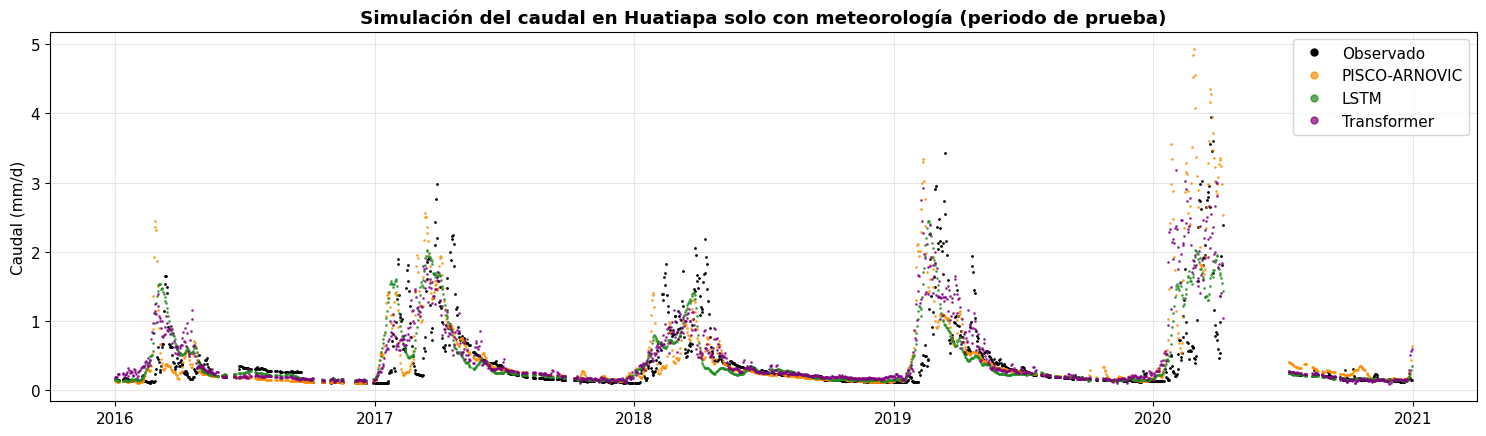

In [ ]:
p = per_s['prueba']
obs_te = q_obs[ts][p]
predicciones_sim = {
    'PISCO-ARNOVIC': df['flow_sim'].values[ts][p],
    'LSTM': a_caudal(lstm_sim.predict(Xs[p], verbose=0).ravel()),
    'Transformer': a_caudal(transformer.predict(Xs[p], verbose=0).ravel()),
}
print(f"{'Simulación, prueba 2016–2020':<30s} {'NSE':>6s} {'KGE':>6s}")
print('-' * 44)
for nombre, pred in predicciones_sim.items():
    print(f"{nombre:<30s} {nse(obs_te, pred):6.3f} {kge(obs_te, pred):6.3f}")

fig, ax = plt.subplots(figsize=(15, 4.5))
f = fechas_s[p]
ax.plot(f, obs_te, 'k.', ms=2, label='Observado')
for (nombre, pred), color in zip(predicciones_sim.items(), ['darkorange', 'forestgreen', 'purple']):
    ax.plot(f, pred, '.', ms=2, color=color, alpha=0.7, label=nombre)
ax.set_ylabel('Caudal (mm/d)'); ax.legend(markerscale=5); ax.grid(alpha=0.3)
ax.set_title('Simulación del caudal en Huatiapa solo con meteorología (periodo de prueba)', fontweight='bold')
plt.tight_layout(); plt.show()

### ¿A qué días pasados presta atención el Transformer?

Una ventaja de la atención es que podemos **mirar sus pesos**. Tomamos la fila del **último día** (el token que produce la predicción) en el último bloque y la promediamos sobre las cabezas y los días de prueba.

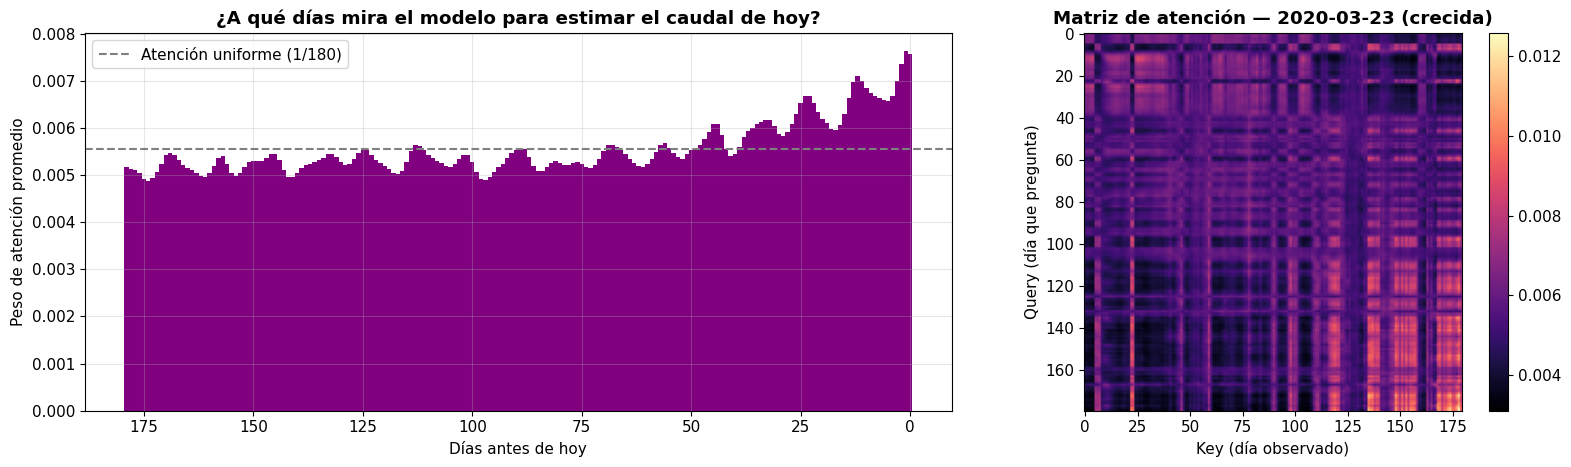

Atención a los días   0–7   atrás:  4.9%   (si fuera uniforme:  3.9%)
Atención a los días   7–30  atrás: 14.8%   (si fuera uniforme: 12.8%)
Atención a los días  30–90  atrás: 33.1%   (si fuera uniforme: 33.3%)
Atención a los días  90–180 atrás: 47.1%   (si fuera uniforme: 50.0%)


In [ ]:
pesos = modelo_atencion.predict(Xs[p], verbose=0)[-1]   # último bloque: (muestras, cabezas, 180, 180)
atencion_hoy = pesos[:, :, -1, :].mean(axis=(0, 1))       # cuánto mira "hoy" a cada uno de los 180 días
dias_atras = np.arange(VENTANA - 1, -1, -1)

fig, ejes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={'width_ratios': [1.6, 1]})
ejes[0].bar(dias_atras, atencion_hoy, width=1, color='purple')
ejes[0].axhline(1 / VENTANA, ls='--', color='gray', label='Atención uniforme (1/180)')
ejes[0].invert_xaxis()
ejes[0].set_xlabel('Días antes de hoy'); ejes[0].set_ylabel('Peso de atención promedio')
ejes[0].set_title('¿A qué días mira el modelo para estimar el caudal de hoy?', fontweight='bold')
ejes[0].legend(); ejes[0].grid(alpha=0.3)

i = np.argmax(obs_te)                                     # día de mayor caudal en la prueba
im = ejes[1].imshow(pesos[i].mean(axis=0), cmap='magma')
ejes[1].set_xlabel('Key (día observado)'); ejes[1].set_ylabel('Query (día que pregunta)')
ejes[1].set_title(f'Matriz de atención — {fechas_s[p][i].date()} (crecida)', fontweight='bold')
plt.colorbar(im, ax=ejes[1])
plt.tight_layout(); plt.show()

for rango in [(0, 7), (7, 30), (30, 90), (90, 180)]:
    sel = (dias_atras >= rango[0]) & (dias_atras < rango[1])
    print(f"Atención a los días {rango[0]:>3d}–{rango[1]:<3d} atrás: {atencion_hoy[sel].sum():5.1%}"
          f"   (si fuera uniforme: {sel.mean():5.1%})")

### ¿Qué observamos?

- El Transformer **no supera claramente** a la LSTM con los datos de una sola cuenca (los resultados varían entre ejecuciones). Tiene más parámetros y menos "sesgo inductivo": no sabe de antemano que el orden importa, y debe aprenderlo de los datos.
- Este resultado coincide con la investigación en hidrología: entrenando con **una cuenca**, las LSTM siguen siendo muy competitivas. Los Transformers brillan cuando hay **muchísimos datos**.
- Los pesos de atención son una herramienta de **interpretación**: muestran qué ventana temporal usa el modelo. Con una cuenca suelen salir bastante **repartidos** (cerca de la línea uniforme), con picos en el día actual y en la temporada de lluvias anterior. Compáralo con el tiempo de respuesta de la cuenca. Ojo: atención **no es** causalidad, y las otras capas también mezclan información.

👉 **Si los Transformers necesitan muchos datos, ¿qué pasa si alguien entrena uno con *millones* de series de tiempo de todo el mundo?** Eso es un modelo fundacional.

# 5. Modelos fundacionales

Un **modelo fundacional** (*foundation model*) es un modelo grande, normalmente un Transformer, que:

1. Se **preentrena** una sola vez, con un costo enorme, sobre datos masivos y diversos.
2. Aprende **representaciones generales** (del lenguaje, de las imágenes, de cómo evolucionan las series de tiempo).
3. Se **reutiliza** en tareas nuevas:
   - **Zero-shot:** usarlo directamente, sin entrenar nada.
   - **Few-shot / in-context:** darle algunos ejemplos en la entrada.
   - **Fine-tuning:** ajustar sus pesos con pocos datos propios.

```
             PREENTRENAMIENTO (una vez, miles de GPU)              USO (tú, en Colab)
  millones de series / imágenes / textos ──► MODELO FUNDACIONAL ──► zero-shot · fine-tuning
```

### Modelos fundacionales relevantes para las ciencias ambientales

| Dominio | Modelos | Qué hacen | Relevancia para el Perú |
|---|---|---|---|
| Lenguaje | GPT, Claude, Gemini, Llama | Texto, código, razonamiento | Analizar informes del SENAMHI/INDECI, programar |
| **Series de tiempo** | **Chronos / Chronos-2** (Amazon), TimesFM (Google), Moirai (Salesforce) | Pronóstico *zero-shot* de cualquier serie | Caudales, demanda eléctrica, PM2.5, precios agrícolas |
| Pronóstico del tiempo | GraphCast, GenCast (Google DeepMind), Pangu-Weather, Aurora (Microsoft) | Pronóstico global en minutos, comparable a los centros numéricos | Pronósticos a 10 días sin supercomputadora |
| Observación de la Tierra | Prithvi (NASA–IBM), Clay, AlphaEarth Foundations (Google) | Representaciones de imágenes satelitales | Cobertura, inundaciones y quemas con pocos ejemplos; los *embeddings* de AlphaEarth están en Google Earth Engine (Lab 6) |
| Hidrología | Google Flood Hub (LSTM global, Nearing et al. 2024) | Alertas de crecidas en cuencas sin aforos | Cubre ríos del Perú |

## 5.1 Chronos: pronosticar caudales sin entrenar

**Chronos** (Ansari et al., 2024) es una familia de Transformers preentrenados con un gran corpus de series de tiempo públicas más series sintéticas generadas con procesos gaussianos. Chronos-Bolt se entrenó con casi 100 mil millones de observaciones. **Que sepamos, nunca vio el río Majes** (ver la sección 5.3 sobre contaminación de datos). Le damos los últimos 512 días de caudal y le pedimos los 7 días siguientes.

Usamos **Chronos-Bolt-small** (48 M de parámetros, ~190 MB). Produce **cuantiles**: no solo un valor, sino un rango de incertidumbre.

Lo comparamos con la tarea **A2 del Lab 9_3** (pronóstico con asimilación del caudal observado): persistencia y una LSTM **entrenada con 13 años de datos de esta cuenca**.

In [ ]:
# Serie de caudal "conocida hasta hoy": observado y, en los huecos, el simulado por ARNOVIC
serie = camels['flow_obs'].fillna(camels['flow_sim'])
CONTEXTO, H_MAX = 512, 7
emision = serie.loc['2015-12-25':'2020-12-24'].index          # días en que se emite cada pronóstico
pos = np.array([serie.index.get_loc(f) for f in emision])

def evaluar_pronostico(pred_por_h):
    # pred_por_h[H] = vector de pronósticos (uno por día de emisión) para el horizonte H
    filas = {}
    for H, pred in pred_por_h.items():
        objetivo = camels['flow_obs'].values[pos + H]
        fecha_obj = serie.index[pos + H]
        ok = ~np.isnan(objetivo) & (fecha_obj >= '2016-01-01') & (fecha_obj <= '2020-12-31') & ~np.isnan(pred)
        filas[H] = nse(objetivo[ok], pred[ok])
    return filas

resultados = {
    'Persistencia': evaluar_pronostico({H: serie.values[pos] for H in [1, 3, 7]}),
    'PISCO-ARNOVIC': evaluar_pronostico({H: camels['flow_sim'].values[pos + H] for H in [1, 3, 7]}),
}
pd.DataFrame(resultados).T.round(3).add_prefix('NSE a ').add_suffix(' d')

,NSE a 1 d,NSE a 3 d,NSE a 7 d
Persistencia,0.917,0.670,0.348
PISCO-ARNOVIC,-0.296,-0.295,-0.295


In [ ]:
# LSTM entrenada con datos de la cuenca (igual que la A2 del Lab 9_3: predice el CAMBIO respecto a hoy)
q_entrada = np.log(serie.loc[df.index].values + 0.05)
q_entrada_n = (q_entrada - q_media) / q_desv
q_bandera = df['flow_obs'].notna().values.astype('float32')
X_pron = np.column_stack([X_met_n, q_entrada_n, q_bandera]).astype('float32')
fila_df = {f: i for i, f in enumerate(df.index)}

pred_lstm = {}
for H in [1, 3, 7]:
    Xp, tp, _, per_p = crear_ventanas(X_pron, 90, horizonte=H)
    base = q_entrada_n[tp]
    keras.utils.set_random_seed(42)
    modelo = keras.Sequential([keras.Input(shape=Xp.shape[1:]), layers.LSTM(32), layers.Dropout(0.2),
                               layers.Dense(1)], name=f'LSTM_H{H}')
    entrenar(modelo, Xp, (q_n[tp + H] - base).astype('float32'), per_p)
    # Pronosticar para cada día de emisión (mismas fechas que Chronos)
    filas = np.array([fila_df[f] for f in emision])
    Xe = np.stack([X_pron[i - 89:i + 1] for i in filas])
    pred_lstm[H] = a_caudal(modelo.predict(Xe, verbose=0).ravel() + q_entrada_n[filas])

resultados['LSTM entrenada (Lab 9_3)'] = evaluar_pronostico(pred_lstm)
pd.DataFrame(resultados).T.round(3).add_prefix('NSE a ').add_suffix(' d')

  LSTM_H1        5,281 parámetros | 13 épocas |   6.0 s
  LSTM_H3        5,281 parámetros |  7 épocas |   4.1 s
  LSTM_H7        5,281 parámetros |  7 épocas |   3.6 s


,NSE a 1 d,NSE a 3 d,NSE a 7 d
Persistencia,0.917,0.670,0.348
PISCO-ARNOVIC,-0.296,-0.295,-0.295
LSTM entrenada (Lab 9_3),0.922,0.702,0.458


In [ ]:
from chronos import BaseChronosPipeline

dispositivo = 'cuda' if torch.cuda.is_available() else 'cpu'
t0 = time.time()
chronos_bolt = BaseChronosPipeline.from_pretrained('amazon/chronos-bolt-small', device_map=dispositivo,
                                                   torch_dtype=torch.float32)
print(f"Chronos-Bolt-small cargado en {time.time() - t0:.0f} s")

contextos = torch.tensor(np.stack([serie.values[p - CONTEXTO + 1:p + 1] for p in pos]), dtype=torch.float32)
print(f"Contextos: {tuple(contextos.shape)}  → (días de emisión, {CONTEXTO} días de historia)")

t0 = time.time()
cuantiles, _ = chronos_bolt.predict_quantiles(contextos, prediction_length=H_MAX,
                                              quantile_levels=[0.1, 0.5, 0.9])
cuantiles = cuantiles.numpy()                                   # (emisiones, 7 días, 3 cuantiles)
print(f"{len(pos)} pronósticos de 7 días en {time.time() - t0:.1f} s — ¡sin entrenar nada!")

resultados['Chronos-Bolt (zero-shot)'] = evaluar_pronostico({H: cuantiles[:, H - 1, 1] for H in [1, 3, 7]})
pd.DataFrame(resultados).T.round(3).add_prefix('NSE a ').add_suffix(' d')

config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  191MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Chronos-Bolt-small cargado en 4 s
Contextos: (1827, 512)  → (días de emisión, 512 días de historia)
1827 pronósticos de 7 días en 5.9 s — ¡sin entrenar nada!


,NSE a 1 d,NSE a 3 d,NSE a 7 d
Persistencia,0.917,0.670,0.348
PISCO-ARNOVIC,-0.296,-0.295,-0.295
LSTM entrenada (Lab 9_3),0.922,0.702,0.458
Chronos-Bolt (zero-shot),0.908,0.684,0.442


### Pronóstico probabilístico

A diferencia de nuestra LSTM, que da un solo número, Chronos entrega **cuantiles**. La banda entre el percentil 10 y el 90 debería contener el valor observado ~80% de las veces. Esa información es la que necesita un tomador de decisiones (ANA, autoridad de riego, INDECI) para gestionar el riesgo de una crecida.

Cobertura de la banda P10–P90 a 7 días: 83%  (ideal ≈ 80%)


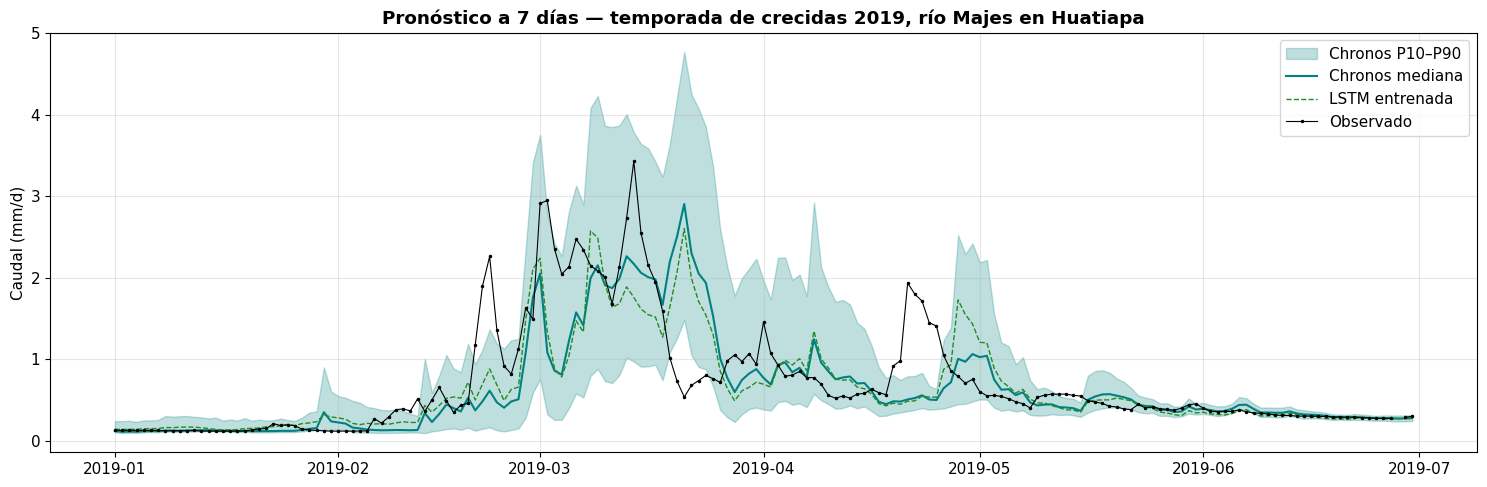

In [ ]:
H = 7
objetivo = camels['flow_obs'].values[pos + H]
fecha_obj = serie.index[pos + H]
ok = ~np.isnan(objetivo)
dentro = (objetivo[ok] >= cuantiles[ok, H - 1, 0]) & (objetivo[ok] <= cuantiles[ok, H - 1, 2])
print(f"Cobertura de la banda P10–P90 a {H} días: {dentro.mean():.0%}  (ideal ≈ 80%)")

tramo = (fecha_obj >= '2019-01-01') & (fecha_obj <= '2019-06-30')
fig, ax = plt.subplots(figsize=(15, 5))
ax.fill_between(fecha_obj[tramo], cuantiles[tramo, H - 1, 0], cuantiles[tramo, H - 1, 2],
                color='teal', alpha=0.25, label='Chronos P10–P90')
ax.plot(fecha_obj[tramo], cuantiles[tramo, H - 1, 1], color='teal', lw=1.5, label='Chronos mediana')
ax.plot(fecha_obj[tramo], pred_lstm[H][tramo], color='forestgreen', lw=1, ls='--', label='LSTM entrenada')
ax.plot(fecha_obj[tramo], objetivo[tramo], 'k.-', ms=3, lw=0.8, label='Observado')
ax.set_ylabel('Caudal (mm/d)'); ax.legend(); ax.grid(alpha=0.3)
ax.set_title(f'Pronóstico a {H} días — temporada de crecidas 2019, río Majes en Huatiapa', fontweight='bold')
plt.tight_layout(); plt.show()

## 5.2 Chronos-2: añadir covariables meteorológicas

**Chronos-2** (2025, 120 M de parámetros, ~480 MB) acepta, además de la serie objetivo, **covariables**: otras series que ayudan a pronosticar. Le pasamos la historia de precipitación, temperatura media, radiación y presión de vapor de la cuenca (los mismos 512 días del contexto), también *zero-shot*. **No recibe meteorología del futuro**: es un pronóstico real, en las mismas condiciones que la LSTM y la persistencia.

⏱️ En CPU tarda ~1–2 minutos; en GPU, segundos.

In [ ]:
COVARIABLES = ['prec', 'tmean', 'srad', 'vprp']
chronos2 = BaseChronosPipeline.from_pretrained('amazon/chronos-2', device_map=dispositivo,
                                               torch_dtype=torch.float32)

entradas = [{'target': serie.values[p - CONTEXTO + 1:p + 1].astype('float32'),
             'past_covariates': {c: camels[c].values[p - CONTEXTO + 1:p + 1].astype('float32')
                                 for c in COVARIABLES}}
            for p in pos]

t0 = time.time()
cuantiles2, _ = chronos2.predict_quantiles(entradas, prediction_length=H_MAX, quantile_levels=[0.1, 0.5, 0.9])
mediana2 = np.stack([c[0, :, 1].numpy() for c in cuantiles2])   # (emisiones, 7 días)
print(f"Chronos-2 con covariables: {time.time() - t0:.0f} s")

resultados['Chronos-2 + meteorología pasada (zero-shot)'] = evaluar_pronostico({H: mediana2[:, H - 1] for H in [1, 3, 7]})
tabla = pd.DataFrame(resultados).T.round(3).add_prefix('NSE a ').add_suffix(' d')
tabla

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  478MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Chronos-2 con covariables: 30 s


,NSE a 1 d,NSE a 3 d,NSE a 7 d
Persistencia,0.917,0.670,0.348
PISCO-ARNOVIC,-0.296,-0.295,-0.295
LSTM entrenada (Lab 9_3),0.922,0.702,0.458
Chronos-Bolt (zero-shot),0.908,0.684,0.442
Chronos-2 + meteorología pasada (zero-shot),0.915,0.709,0.496


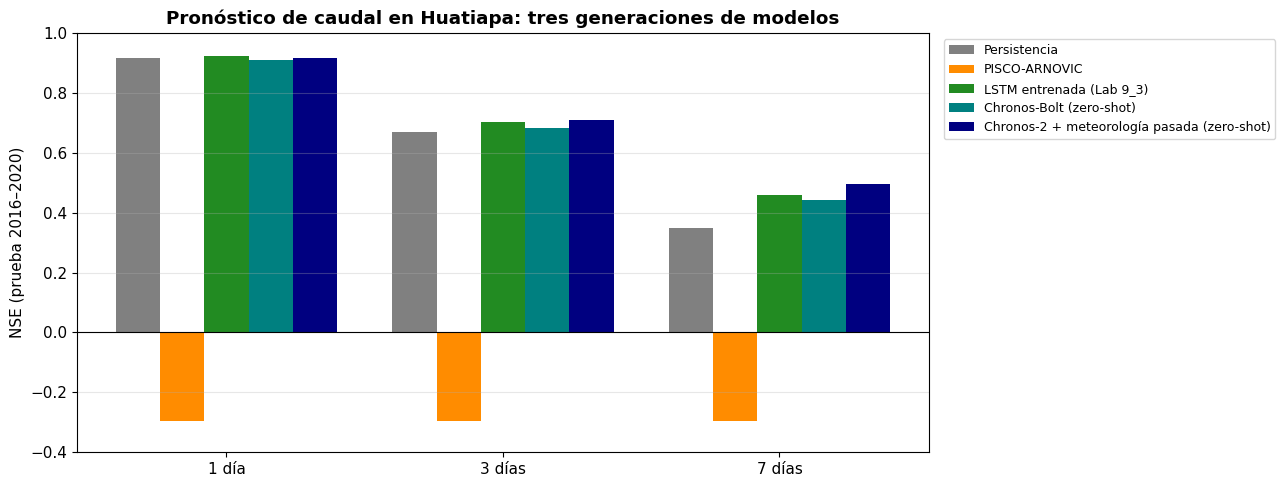

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))
colores = ['gray', 'darkorange', 'forestgreen', 'teal', 'navy']
ancho = 0.16
for k, (nombre, fila) in enumerate(resultados.items()):
    ax.bar(np.arange(3) + (k - 2) * ancho, [fila[H] for H in [1, 3, 7]], ancho,
           color=colores[k], label=nombre)
ax.axhline(0, color='k', lw=0.8)
ax.set_xticks(range(3)); ax.set_xticklabels(['1 día', '3 días', '7 días'])
ax.set_ylabel('NSE (prueba 2016–2020)'); ax.set_ylim(-0.4, 1)
ax.set_title('Pronóstico de caudal en Huatiapa: tres generaciones de modelos', fontweight='bold')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

### ¿Qué observamos?

- **Chronos-Bolt**, que **nunca vio el río Majes**, queda muy cerca de una LSTM entrenada con 13 años de datos de la cuenca, y supera a la persistencia a 3 y 7 días.
- **Chronos-2 con covariables meteorológicas** es el mejor modelo a 3 y 7 días, también sin entrenar nada.
- Los valores de la LSTM varían algo entre ejecuciones; los de Chronos son deterministas.
- A 1 día nadie supera claramente a la persistencia: el río tiene mucha inercia.
- Los modelos fundacionales **democratizan** el pronóstico: una oficina regional sin largos registros históricos ni especialistas en deep learning puede obtener pronósticos razonables, con incertidumbre, en segundos.

## 5.3 Pensamiento crítico: limitaciones

| Aspecto | Pregunta que debes hacerte |
|---|---|
| **Contaminación de datos** | ¿El modelo pudo ver esta serie (o una muy parecida) durante el preentrenamiento? Si es así, la evaluación es optimista. Evalúa siempre con datos posteriores a su entrenamiento o propios. |
| **Física** | Un modelo estadístico no garantiza conservación de masa. ¿Puede pronosticar un caudal mayor que toda la lluvia posible? |
| **Eventos extremos** | ¿Funciona en un Niño Costero como el de 2017, o ante una situación que nunca ocurrió en sus datos? |
| **Interpretabilidad** | Con millones de parámetros, explicar *por qué* pronostica algo es difícil. |
| **Costo y energía** | El preentrenamiento consume enormes recursos, aunque el uso (inferencia) sea barato. |
| **Soberanía de datos** | Modelos de empresas extranjeras, licencias y dependencia tecnológica: ¿qué implica para las instituciones peruanas? |

Una dirección muy activa es la **hibridación**: modelos que combinan física (balance hídrico) con redes neuronales, y el ***fine-tuning*** de modelos fundacionales con datos locales del SENAMHI.

# 6. ¿Qué generación uso?

| Situación | Recomendación |
|---|---|
| Datos tabulares, pocos datos | Random Forest / XGBoost (Lab 8) |
| Imágenes de un problema específico | CNN o *transfer learning* (Lab 9_2) |
| Series de una cuenca con buenos registros | LSTM: robusta, eficiente, el estándar en hidrología (Lab 9_3) |
| Muchísimos datos (miles de cuencas / estaciones) | Transformer o LSTM regional |
| Pocos datos o necesidad de un resultado rápido | **Modelo fundacional zero-shot** (Chronos, TimesFM) |
| Imágenes satelitales con pocas etiquetas | Embeddings de un modelo fundacional (Prithvi, AlphaEarth) + un clasificador simple |
| Siempre | **Compara con una línea base simple** (persistencia, climatología, modelo físico) |

---
## 🔬 Ejercicios

1. **Arquitectura del Transformer.** Cambia `n_bloques` (1, 2, 4), `cabezas` (1, 4, 8) y `d_model` (16, 32, 64). ¿Cómo cambian el NSE, el número de parámetros y el tiempo? ¿Hay un tamaño "óptimo" para una sola cuenca?
2. **Sin codificación posicional.** Elimina la capa `PosicionSinusoidal` y reentrena. ¿Qué pasa con el NSE y con el patrón de atención? Explica por qué.
3. **Interpretación.** Según la gráfica de atención, ¿qué porcentaje de la atención va a los últimos 30 días? ¿Concuerda con la correlación entre la lluvia acumulada y el caudal que vimos en el Lab 9_3?
4. **Contexto de Chronos.** Repite el pronóstico de Chronos-Bolt con `CONTEXTO = 64`, `256` y `1024`. ¿Cuánta historia necesita el modelo?
5. **Tamaño del modelo fundacional.** Prueba `amazon/chronos-bolt-tiny` (9 M) y `amazon/chronos-bolt-base` (205 M). ¿Mejora el pronóstico con el tamaño? ¿Y el tiempo?
6. **Calibración.** Calcula la cobertura de la banda P10–P90 para H = 1, 3 y 7 días. ¿Está bien calibrado Chronos?
7. **Otra serie peruana.** Aplica Chronos-Bolt *zero-shot* a la temperatura diaria de la estación SENAMHI Ñaña (`3_clases/data/Senamhi/qc00000543_ñaña.txt`) o a datos horarios de PM2.5 de Lima. ¿Supera a la persistencia?
8. **Debate.** ¿Debería el SENAMHI reemplazar sus modelos hidrológicos por modelos fundacionales? Argumenta a favor y en contra usando la tabla de la sección 5.3.

---
## Resumen

| Concepto | Conclusión clave |
|---|---|
| Transformer | Arquitectura basada en atención; procesa toda la secuencia en paralelo |
| Token | La unidad que procesa el modelo: palabra, parche de imagen, día de una serie |
| Codificación posicional | La atención no sabe de orden; hay que sumar la posición a cada token |
| Multi-cabeza | Varias atenciones en paralelo, cada una especializada en un patrón |
| Residual + LayerNorm | Permiten apilar muchos bloques sin que el gradiente se desvanezca |
| Máscara causal | En los modelos generativos, cada posición solo mira al pasado |
| Modelo fundacional | Transformer grande preentrenado con datos masivos y reutilizable |
| Zero-shot | Usar el modelo en una tarea nueva sin entrenarlo |
| Fine-tuning | Ajustar un modelo preentrenado con pocos datos propios |
| Pronóstico probabilístico | Cuantiles en lugar de un solo valor: cuantifican la incertidumbre |
| Regla de oro | Más grande no siempre es mejor: compara siempre con líneas base y con la LSTM |

### Deep Learning en el curso

| Lab | Generación | Datos | Aplicación peruana |
|---|---|---|---|
| 9_1 | MLP | Tabulares | Cobertura desde índices espectrales |
| 9_2 | CNN | Imágenes | Parches satelitales, deforestación |
| 9_3 | RNN / LSTM | Series de tiempo | Caudales del Majes, Titicaca |
| **9_4** | **Transformer / Fundacional** | **Secuencias, cualquier modalidad** | **Pronóstico zero-shot de caudales, interpretación con atención** |

## Lecturas recomendadas

- Vaswani, A. et al. (2017). *Attention Is All You Need.* NeurIPS.
- Alammar, J. *The Illustrated Transformer* — jalammar.github.io.
- Bommasani, R. et al. (2021). *On the Opportunities and Risks of Foundation Models.* Stanford CRFM.
- Ansari, A. F. et al. (2024). *Chronos: Learning the Language of Time Series.* TMLR.
- Lam, R. et al. (2023). *Learning skillful medium-range global weather forecasting* (GraphCast). Science.
- Nearing, G. et al. (2024). *Global prediction of extreme floods in ungauged watersheds.* Nature.
- Kratzert, F. et al. (2019). *Towards learning universal, regional, and local hydrological behaviors via machine learning applied to large-sample datasets.* HESS.